# Exercise 7: Cost-Minimized Unrestricted Classification
**Team:** Swiss Quant Industrial

The Exercise 5 classifier is PLC-compatible, but it is constrained to three raw machine features and a shallow rule. In this notebook Dave's server upgrade is used differently: we train an unrestricted all-feature classifier and tune the decision threshold to minimize the custom production-cost metric.

Target convention used throughout:

- `0 = BAD`
- `1 = GOOD`

Custom metric:

- `BAD -> GOOD` error: bad batch shipped, `500 CHF`
- `GOOD -> BAD` error: good batch wasted, `10 CHF`

The notebook compares the new model against the saved Exercise 5 PLC predictions on the same held-out test rows.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from IPython.display import Markdown, display
from sklearn.metrics import confusion_matrix, roc_auc_score, average_precision_score
from sklearn.model_selection import train_test_split

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("deep")
pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

RANDOM_STATE = 42
BAD_CLASS = 0
GOOD_CLASS = 1
LABEL_NAMES = {BAD_CLASS: "BAD", GOOD_CLASS: "GOOD"}

BAD_SHIPPED_COST_CHF = 500
GOOD_WASTED_COST_CHF = 10
TEST_SIZE = 0.20
VALIDATION_SIZE_WITHIN_TRAIN = 0.25


## 1. Load the Exercise 3 table and Exercise 5 baseline

The data split preserves the original row index. That index is used to align the saved Exercise 5 out-of-fold PLC prediction for each test row.

In [2]:
CANDIDATE_BASE_DIRS = [
    Path.cwd(),
    Path.cwd() / "Case",
    Path.cwd().parent,
]


def resolve_base_dir() -> Path:
    for candidate in CANDIDATE_BASE_DIRS:
        candidate = candidate.resolve()
        if (candidate / "outputs" / "exercise3_master_table_case_level.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find outputs/exercise3_master_table_case_level.csv. "
        "Start Jupyter from the project root or Case folder."
    )


BASE_DIR = resolve_base_dir()
DATA_PATH = BASE_DIR / "outputs" / "exercise3_master_table_case_level.csv"
PLC_PREDICTION_PATH = BASE_DIR / "outputs" / "exercise5_plc_predictions.csv"
TARGET_COLUMN = "Manual_Label"
LABEL_AVAILABLE_COLUMN = "label_available"
FEATURE_PREFIX = "feature_"

raw = pd.read_csv(DATA_PATH)
if LABEL_AVAILABLE_COLUMN in raw.columns:
    label_mask = raw[LABEL_AVAILABLE_COLUMN].astype(str).str.lower().isin(["true", "1", "yes"])
    df = raw.loc[label_mask].copy()
else:
    df = raw.copy()

df = df.dropna(subset=[TARGET_COLUMN]).copy()
df[TARGET_COLUMN] = df[TARGET_COLUMN].astype(int)

feature_cols = [col for col in df.columns if col.startswith(FEATURE_PREFIX)]
X = df[feature_cols].apply(pd.to_numeric, errors="coerce")
y = df[TARGET_COLUMN]
row_index = df.index

X_train_full, X_test, y_train_full, y_test, idx_train_full, idx_test = train_test_split(
    X,
    y,
    row_index,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=VALIDATION_SIZE_WITHIN_TRAIN,
    random_state=RANDOM_STATE,
    stratify=y_train_full,
)

split_summary = pd.DataFrame(
    [
        {"split": "train", "rows": len(y_train), "bad": int((y_train == BAD_CLASS).sum()), "good": int((y_train == GOOD_CLASS).sum())},
        {"split": "validation", "rows": len(y_val), "bad": int((y_val == BAD_CLASS).sum()), "good": int((y_val == GOOD_CLASS).sum())},
        {"split": "test", "rows": len(y_test), "bad": int((y_test == BAD_CLASS).sum()), "good": int((y_test == GOOD_CLASS).sum())},
    ]
)
split_summary["bad_share"] = split_summary["bad"] / split_summary["rows"]

print(f"Base directory: {BASE_DIR}")
print(f"Master table: {DATA_PATH}")
print(f"Exercise 5 predictions: {PLC_PREDICTION_PATH}")
print(f"Feature columns used by Exercise 7: {len(feature_cols)}")
display(split_summary)


Base directory: /Users/karimmaass/Desktop/ETH Semester 2/AI in PM/AI in PM
Master table: /Users/karimmaass/Desktop/ETH Semester 2/AI in PM/AI in PM/outputs/exercise3_master_table_case_level.csv
Exercise 5 predictions: /Users/karimmaass/Desktop/ETH Semester 2/AI in PM/AI in PM/outputs/exercise5_plc_predictions.csv
Feature columns used by Exercise 7: 33


,split,rows,bad,good,bad_share
0,train,842,409,433,0.4857
1,validation,281,137,144,0.4875
2,test,281,136,145,0.4840


## 2. Define the cost metric

Accuracy is reported, but it is not the optimization target. The model is selected by total CHF cost.

In [3]:
def predict_from_bad_probability(prob_bad, threshold):
    """Predict BAD when the model's BAD probability is at least the threshold."""
    return pd.Series(np.where(prob_bad >= threshold, BAD_CLASS, GOOD_CLASS))


def confusion_counts(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[BAD_CLASS, GOOD_CLASS])
    return {
        "bad_correct": int(cm[0, 0]),
        "bad_shipped": int(cm[0, 1]),
        "good_wasted": int(cm[1, 0]),
        "good_correct": int(cm[1, 1]),
    }


def production_cost_chf(y_true, y_pred):
    counts = confusion_counts(y_true, y_pred)
    return (
        counts["bad_shipped"] * BAD_SHIPPED_COST_CHF
        + counts["good_wasted"] * GOOD_WASTED_COST_CHF
    )


def summary_row(y_true, y_pred, model_name, threshold=None):
    counts = confusion_counts(y_true, y_pred)
    rows = len(y_true)
    cost = production_cost_chf(y_true, y_pred)
    return {
        "model": model_name,
        "threshold": threshold,
        "bad_shipped": counts["bad_shipped"],
        "good_wasted": counts["good_wasted"],
        "bad_shipped_cost_chf": counts["bad_shipped"] * BAD_SHIPPED_COST_CHF,
        "good_wasted_cost_chf": counts["good_wasted"] * GOOD_WASTED_COST_CHF,
        "cost_chf": cost,
        "accuracy": (counts["bad_correct"] + counts["good_correct"]) / rows,
    }


def threshold_curve(y_true, prob_bad):
    thresholds = np.unique(np.r_[np.linspace(0.0, 1.0, 1001), prob_bad])
    rows = []
    for threshold in thresholds:
        y_pred = predict_from_bad_probability(prob_bad, threshold)
        row = summary_row(y_true, y_pred, "threshold candidate", threshold)
        rows.append(row)
    curve = pd.DataFrame(rows)
    curve = curve.sort_values(
        ["cost_chf", "bad_shipped", "good_wasted", "threshold"],
        ascending=[True, True, True, True],
    ).reset_index(drop=True)
    return curve


print(
    f"Cost metric: {BAD_SHIPPED_COST_CHF} CHF per BAD -> GOOD error; "
    f"{GOOD_WASTED_COST_CHF} CHF per GOOD -> BAD error."
)


Cost metric: 500 CHF per BAD -> GOOD error; 10 CHF per GOOD -> BAD error.


## 3. Train unrestricted XGBoost

XGBoost is trained to estimate `P(BAD)`. The cost asymmetry is handled in threshold selection rather than by the default `0.5` classifier cutoff.

In [4]:
y_train_bad_positive = (y_train == BAD_CLASS).astype(int)
y_val_bad_positive = (y_val == BAD_CLASS).astype(int)
y_test_bad_positive = (y_test == BAD_CLASS).astype(int)

xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    min_child_weight=1,
    reg_lambda=1.0,
    scale_pos_weight=1.0,
    random_state=RANDOM_STATE,
    eval_metric="logloss",
    n_jobs=-1,
)

xgb_model.fit(X_train, y_train_bad_positive, verbose=False)

val_prob_bad = xgb_model.predict_proba(X_val)[:, 1]
test_prob_bad = xgb_model.predict_proba(X_test)[:, 1]

probability_quality = pd.DataFrame(
    [
        {"split": "validation", "roc_auc_for_BAD": roc_auc_score(y_val_bad_positive, val_prob_bad), "average_precision_for_BAD": average_precision_score(y_val_bad_positive, val_prob_bad)},
        {"split": "test", "roc_auc_for_BAD": roc_auc_score(y_test_bad_positive, test_prob_bad), "average_precision_for_BAD": average_precision_score(y_test_bad_positive, test_prob_bad)},
    ]
)
display(probability_quality)


,split,roc_auc_for_BAD,average_precision_for_BAD
0,validation,0.9490,0.9256
1,test,0.9140,0.8834


## 4. Tune threshold on validation cost

The validation set chooses the operating point. The test set is held back until after the threshold has been selected.

**Selected BAD-probability threshold:** `0.043525`

,threshold,cost_chf,bad_shipped,good_wasted,accuracy
0,0.0435,1130,0,113,0.5979
1,0.0433,1140,0,114,0.5943
2,0.0432,1150,0,115,0.5907
3,0.0430,1160,0,116,0.5872
4,0.0431,1160,0,116,0.5872
5,0.0426,1170,0,117,0.5836
6,0.0424,1180,0,118,0.5801
7,0.0422,1190,0,119,0.5765
8,0.0420,1200,0,120,0.5730
9,0.0420,1200,0,120,0.5730


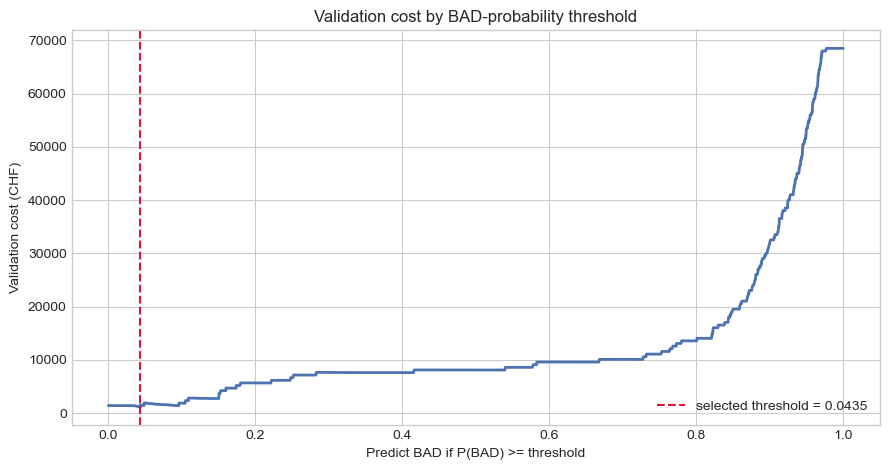

In [5]:
val_curve = threshold_curve(y_val, val_prob_bad)
best_threshold = float(val_curve.loc[0, "threshold"])

threshold_report = val_curve.head(10).copy()
threshold_report["threshold"] = threshold_report["threshold"].round(6)

display(Markdown(f"**Selected BAD-probability threshold:** `{best_threshold:.6f}`"))
display(threshold_report[["threshold", "cost_chf", "bad_shipped", "good_wasted", "accuracy"]])

fig, ax = plt.subplots(figsize=(9, 4.8))
plot_curve = val_curve.sort_values("threshold")
ax.plot(plot_curve["threshold"], plot_curve["cost_chf"], linewidth=2)
ax.axvline(best_threshold, color="crimson", linestyle="--", label=f"selected threshold = {best_threshold:.4f}")
ax.set_title("Validation cost by BAD-probability threshold")
ax.set_xlabel("Predict BAD if P(BAD) >= threshold")
ax.set_ylabel("Validation cost (CHF)")
ax.legend()
plt.tight_layout()
plt.show()


## 5. Compare against Exercise 5 on the same test rows

In [6]:
if not PLC_PREDICTION_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {PLC_PREDICTION_PATH}. Run Exercise 5 through its prediction export cell first."
    )

plc_predictions_raw = pd.read_csv(PLC_PREDICTION_PATH)
required_columns = {"row_index", "actual_label", "plc_pred_label", "selected_triplet", "operator_family"}
missing_columns = required_columns - set(plc_predictions_raw.columns)
if missing_columns:
    raise ValueError(f"Exercise 5 prediction file is missing columns: {sorted(missing_columns)}")

if plc_predictions_raw["row_index"].duplicated().any():
    duplicated = plc_predictions_raw.loc[plc_predictions_raw["row_index"].duplicated(), "row_index"].head().tolist()
    raise ValueError(f"Exercise 5 prediction file contains duplicate row_index values, for example: {duplicated}")

master_labels = df[[TARGET_COLUMN]].rename(columns={TARGET_COLUMN: "master_actual_label"})
plc_prediction_check = plc_predictions_raw.set_index("row_index").join(master_labels, how="left")
missing_master_rows = plc_prediction_check["master_actual_label"].isna().sum()
if missing_master_rows:
    raise ValueError(f"Exercise 5 predictions contain {missing_master_rows} rows that are not in the labeled master table.")

labels_match = (
    plc_prediction_check["actual_label"].astype(int)
    == plc_prediction_check["master_actual_label"].astype(int)
)
if not labels_match.all():
    raise ValueError(f"Exercise 5 prediction labels disagree with the master table for {(~labels_match).sum()} rows.")

expected_labeled_rows = len(df)
if len(plc_predictions_raw) != expected_labeled_rows:
    raise ValueError(
        f"Exercise 5 prediction file has {len(plc_predictions_raw)} rows, "
        f"but the labeled master table has {expected_labeled_rows} rows."
    )

plc_predictions = plc_predictions_raw.set_index("row_index")
missing_test_rows = pd.Index(idx_test).difference(plc_predictions.index)
if len(missing_test_rows):
    raise ValueError(f"Exercise 5 predictions are missing {len(missing_test_rows)} test rows.")

plc_test_predictions = plc_predictions.loc[idx_test]
if not np.array_equal(plc_test_predictions["actual_label"].astype(int).to_numpy(), y_test.astype(int).to_numpy()):
    raise ValueError("Exercise 5 predictions do not align with y_test. Check row_index alignment.")

y_pred_plc = pd.Series(plc_test_predictions["plc_pred_label"].astype(int).to_numpy(), index=y_test.index)
y_pred_xgb_default = predict_from_bad_probability(test_prob_bad, 0.5)
y_pred_xgb_default.index = y_test.index
y_pred_xgb_cost = predict_from_bad_probability(test_prob_bad, best_threshold)
y_pred_xgb_cost.index = y_test.index

plc_full_oof_summary = pd.DataFrame(
    [summary_row(plc_predictions["actual_label"], plc_predictions["plc_pred_label"], "Exercise 5 PLC full OOF export")]
)
plc_file_audit = pd.DataFrame(
    [
        {
            "check": "Exercise 5 prediction rows match labeled master table",
            "value": len(plc_predictions_raw),
            "status": "passed",
        },
        {
            "check": "actual_label matches master Manual_Label",
            "value": int(labels_match.sum()),
            "status": "passed",
        },
        {
            "check": "selected_triplet",
            "value": plc_predictions_raw["selected_triplet"].dropna().unique()[0],
            "status": "passed",
        },
        {
            "check": "operator_family",
            "value": plc_predictions_raw["operator_family"].dropna().unique()[0],
            "status": "passed",
        },
    ]
)

display(Markdown("**Exercise 5 prediction file audit**"))
display(plc_file_audit)
display(Markdown("**Exercise 5 full out-of-fold export summary**"))
display(plc_full_oof_summary[["model", "bad_shipped", "good_wasted", "cost_chf", "accuracy"]])

comparison = pd.DataFrame(
    [
        summary_row(y_test, y_pred_plc, "Exercise 5 PLC rule", threshold=np.nan),
        summary_row(y_test, y_pred_xgb_default, "Exercise 7 XGBoost, default threshold", threshold=0.5),
        summary_row(y_test, y_pred_xgb_cost, "Exercise 7 XGBoost, cost-optimized", threshold=best_threshold),
    ]
)

plc_cost = float(comparison.loc[comparison["model"].eq("Exercise 5 PLC rule"), "cost_chf"].iloc[0])
comparison["cost_difference_vs_plc_chf"] = comparison["cost_chf"] - plc_cost
comparison["cost_reduction_vs_plc_pct"] = np.where(
    comparison["model"].eq("Exercise 5 PLC rule"),
    0.0,
    (plc_cost - comparison["cost_chf"]) / plc_cost,
)

ordered_columns = [
    "model",
    "threshold",
    "bad_shipped",
    "good_wasted",
    "bad_shipped_cost_chf",
    "good_wasted_cost_chf",
    "cost_chf",
    "cost_difference_vs_plc_chf",
    "cost_reduction_vs_plc_pct",
    "accuracy",
]
display(comparison[ordered_columns])

new_cost = float(comparison.loc[comparison["model"].eq("Exercise 7 XGBoost, cost-optimized"), "cost_chf"].iloc[0])
savings = plc_cost - new_cost

if new_cost >= plc_cost:
    raise AssertionError(
        f"Cost-optimized Exercise 7 model did not beat Exercise 5: {new_cost:.0f} CHF vs {plc_cost:.0f} CHF."
    )

print(f"Exercise 7 cost-optimized XGBoost beats Exercise 5 by {savings:,.0f} CHF on the test split.")
print(f"Cost reduction versus PLC baseline: {savings / plc_cost:.1%}")


**Exercise 5 prediction file audit**

,check,value,status
0,Exercise 5 prediction rows match labeled maste...,1404,passed
1,actual_label matches master Manual_Label,1404,passed
2,selected_triplet,"('feature_1', 'feature_2', 'feature_5')",passed
3,operator_family,raw_ratios,passed


**Exercise 5 full out-of-fold export summary**

,model,bad_shipped,good_wasted,cost_chf,accuracy
0,Exercise 5 PLC full OOF export,22,179,12790,0.8568


,model,threshold,bad_shipped,good_wasted,bad_shipped_cost_chf,good_wasted_cost_chf,cost_chf,cost_difference_vs_plc_chf,cost_reduction_vs_plc_pct,accuracy
0,Exercise 5 PLC rule,NaN,6,36,3000,360,3360,0.0000,0.0000,0.8505
1,"Exercise 7 XGBoost, default threshold",0.5000,15,16,7500,160,7660,"4,300.0000",-1.2798,0.8897
2,"Exercise 7 XGBoost, cost-optimized",0.0435,0,123,0,1230,1230,"-2,130.0000",0.6339,0.5623


Exercise 7 cost-optimized XGBoost beats Exercise 5 by 2,130 CHF on the test split.
Cost reduction versus PLC baseline: 63.4%


## 6. Cost and error visualizations

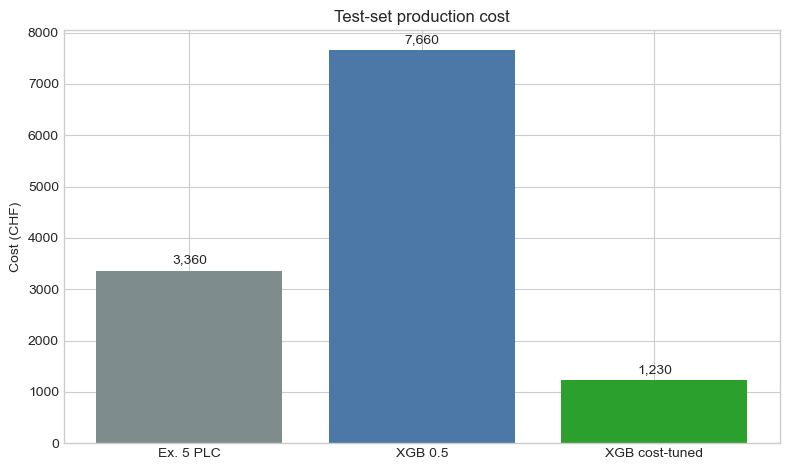

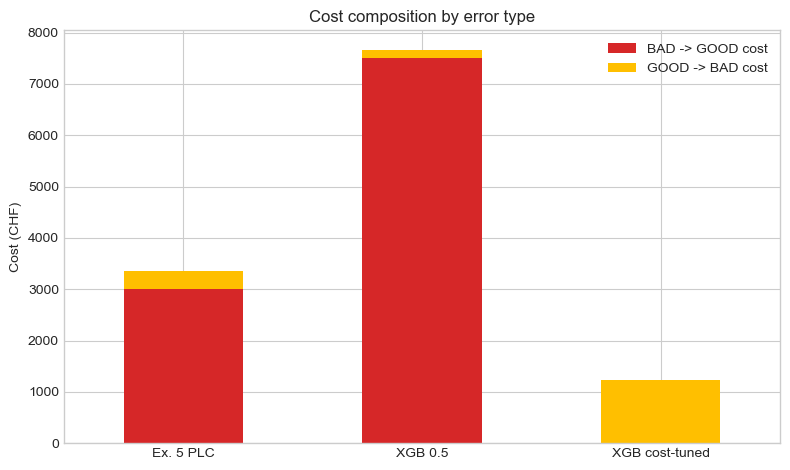

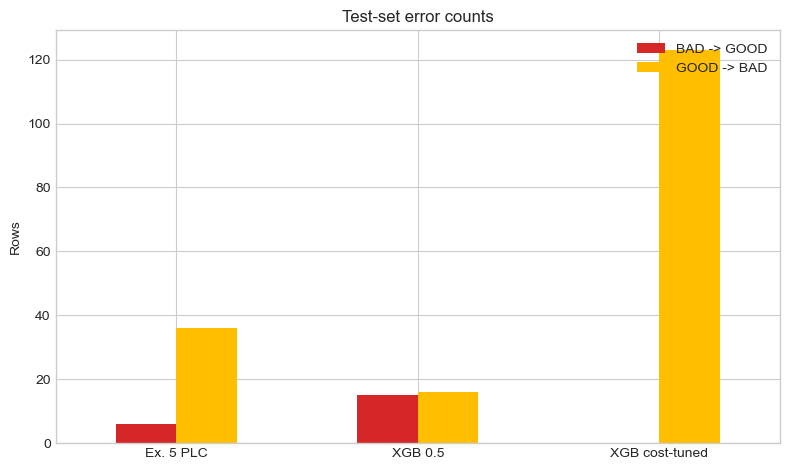

In [7]:
plot_df = comparison.copy()
plot_df["short_model"] = ["Ex. 5 PLC", "XGB 0.5", "XGB cost-tuned"]

fig, ax = plt.subplots(figsize=(8, 4.8))
bars = ax.bar(plot_df["short_model"], plot_df["cost_chf"], color=["#7f8c8d", "#4c78a8", "#2ca02c"])
ax.set_title("Test-set production cost")
ax.set_ylabel("Cost (CHF)")
ax.bar_label(bars, labels=[f"{value:,.0f}" for value in plot_df["cost_chf"]], padding=3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.8))
component_df = plot_df.set_index("short_model")[["bad_shipped_cost_chf", "good_wasted_cost_chf"]]
component_df.plot(kind="bar", stacked=True, ax=ax, color=["#d62728", "#ffbf00"])
ax.set_title("Cost composition by error type")
ax.set_xlabel("")
ax.set_ylabel("Cost (CHF)")
ax.legend(["BAD -> GOOD cost", "GOOD -> BAD cost"], loc="upper right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.8))
err_df = plot_df.set_index("short_model")[["bad_shipped", "good_wasted"]]
err_df.plot(kind="bar", ax=ax, color=["#d62728", "#ffbf00"])
ax.set_title("Test-set error counts")
ax.set_xlabel("")
ax.set_ylabel("Rows")
ax.legend(["BAD -> GOOD", "GOOD -> BAD"], loc="upper right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 7. Confusion matrices

**Exercise 5 PLC rule**

,Pred BAD (0),Pred GOOD (1)
Actual BAD (0),130,6
Actual GOOD (1),36,109


**Exercise 7 XGBoost, default threshold**

,Pred BAD (0),Pred GOOD (1)
Actual BAD (0),121,15
Actual GOOD (1),16,129


**Exercise 7 XGBoost, cost-optimized threshold**

,Pred BAD (0),Pred GOOD (1)
Actual BAD (0),136,0
Actual GOOD (1),123,22


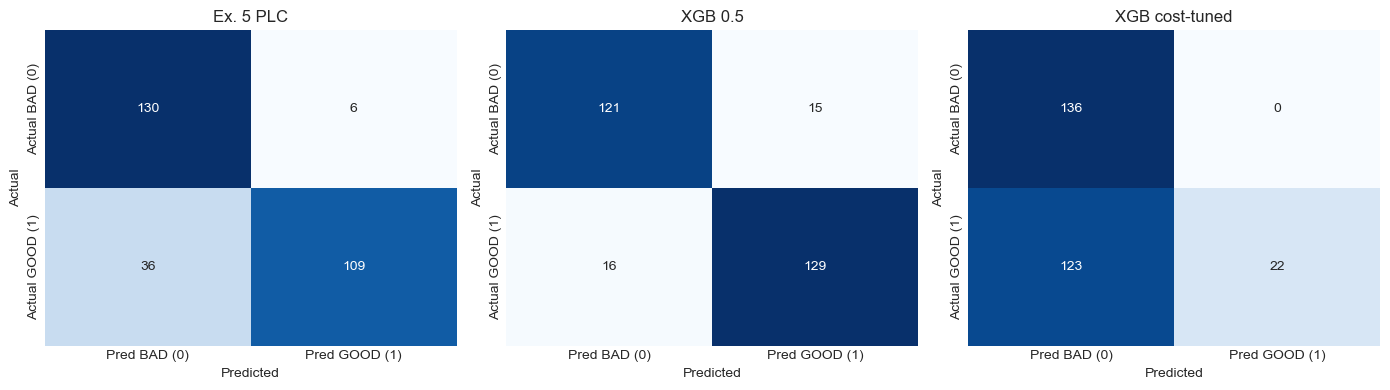

In [8]:
def confusion_frame(y_true, y_pred):
    return pd.DataFrame(
        confusion_matrix(y_true, y_pred, labels=[BAD_CLASS, GOOD_CLASS]),
        index=["Actual BAD (0)", "Actual GOOD (1)"],
        columns=["Pred BAD (0)", "Pred GOOD (1)"],
    )

plc_cm = confusion_frame(y_test, y_pred_plc)
default_cm = confusion_frame(y_test, y_pred_xgb_default)
cost_cm = confusion_frame(y_test, y_pred_xgb_cost)

display(Markdown("**Exercise 5 PLC rule**"))
display(plc_cm)
display(Markdown("**Exercise 7 XGBoost, default threshold**"))
display(default_cm)
display(Markdown("**Exercise 7 XGBoost, cost-optimized threshold**"))
display(cost_cm)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, cm, title in zip(
    axes,
    [plc_cm, default_cm, cost_cm],
    ["Ex. 5 PLC", "XGB 0.5", "XGB cost-tuned"],
):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()


## 8. What the unrestricted model uses

The server-based model is not PLC-limited, so it can use all available sensor features. The plot below reports the most frequently used split features in the trained XGBoost trees.

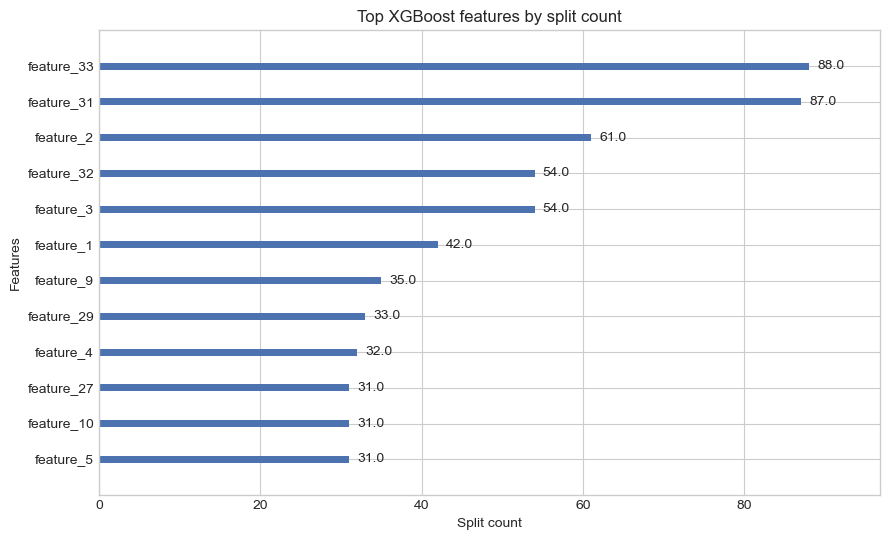

In [9]:
fig, ax = plt.subplots(figsize=(9, 5.5))
xgb.plot_importance(
    xgb_model,
    max_num_features=12,
    importance_type="weight",
    title="Top XGBoost features by split count",
    xlabel="Split count",
    ax=ax,
)
plt.tight_layout()
plt.show()


## 9. Weekly cost saved from avoided wrong classifications

This section estimates how much cost each model saves by avoiding wrong classifications. The reference is the full weekly penalty exposure if every production row were classified incorrectly: each actual BAD row would be shipped as GOOD (`500 CHF`) and each actual GOOD row would be wasted as BAD (`10 CHF`). The model's remaining error cost is subtracted from that exposure.

Observed production volume: **2,006 batches** across **5 production days** (401.2 batches/day). The held-out test split has **136 BAD** and **145 GOOD** rows, giving a maximum wrong-classification exposure of **69,450 CHF**.

,model,bad_shipped,good_wasted,test_wrong_classification_exposure_chf,cost_chf,test_cost_saved_chf,test_cost_saved_pct,estimated_weekly_error_cost_chf,estimated_weekly_cost_saved_chf,incremental_weekly_savings_vs_plc_chf
0,Exercise 5 PLC rule,6,36,69450,3360,66090,0.9516,"23,986.3345","471,802.6335",0.0000
1,"Exercise 7 XGBoost, default threshold",15,16,69450,7660,61790,0.8897,"54,683.1317","441,105.8363","-30,696.7972"
2,"Exercise 7 XGBoost, cost-optimized",0,123,69450,1230,68220,0.9823,"8,780.7117","487,008.2562","15,205.6228"


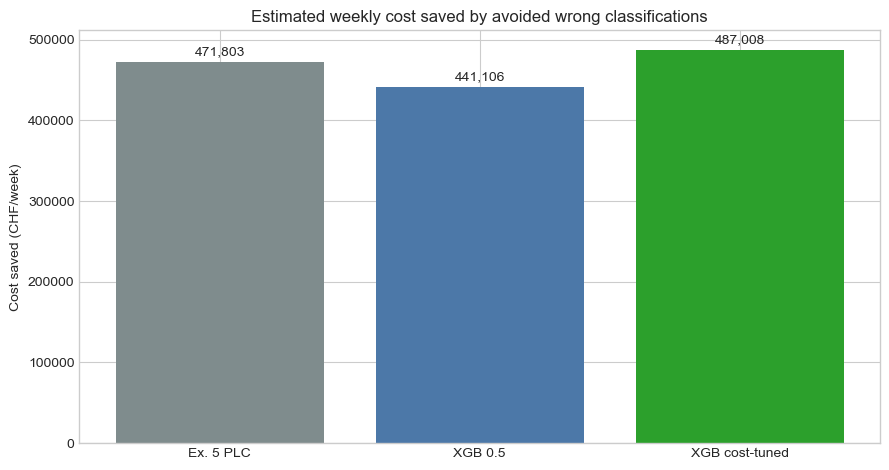

In [10]:
production_dates = pd.to_datetime(raw["production_date"], errors="coerce").dropna()
observed_production_days = int(production_dates.dt.date.nunique())
observed_weekly_batches = int(raw.loc[production_dates.index].shape[0])
observed_batches_per_day = observed_weekly_batches / observed_production_days

test_batches = len(y_test)
test_bad_rows = int((y_test == BAD_CLASS).sum())
test_good_rows = int((y_test == GOOD_CLASS).sum())

# Maximum test-set penalty exposure if every row were classified incorrectly.
test_wrong_classification_exposure_chf = (
    test_bad_rows * BAD_SHIPPED_COST_CHF
    + test_good_rows * GOOD_WASTED_COST_CHF
)

weekly_impact = comparison[["model", "cost_chf", "bad_shipped", "good_wasted", "accuracy"]].copy()
weekly_impact["test_batches"] = test_batches
weekly_impact["test_wrong_classification_exposure_chf"] = test_wrong_classification_exposure_chf
weekly_impact["test_cost_saved_chf"] = test_wrong_classification_exposure_chf - weekly_impact["cost_chf"]
weekly_impact["test_cost_saved_pct"] = (
    weekly_impact["test_cost_saved_chf"] / test_wrong_classification_exposure_chf
)
weekly_impact["test_error_cost_per_batch_chf"] = weekly_impact["cost_chf"] / test_batches
weekly_impact["test_saved_cost_per_batch_chf"] = weekly_impact["test_cost_saved_chf"] / test_batches
weekly_impact["observed_weekly_batches"] = observed_weekly_batches
weekly_impact["estimated_weekly_error_cost_chf"] = (
    weekly_impact["test_error_cost_per_batch_chf"] * observed_weekly_batches
)
weekly_impact["estimated_weekly_cost_saved_chf"] = (
    weekly_impact["test_saved_cost_per_batch_chf"] * observed_weekly_batches
)

plc_weekly_error_cost = float(
    weekly_impact.loc[weekly_impact["model"].eq("Exercise 5 PLC rule"), "estimated_weekly_error_cost_chf"].iloc[0]
)
weekly_impact["incremental_weekly_savings_vs_plc_chf"] = (
    plc_weekly_error_cost - weekly_impact["estimated_weekly_error_cost_chf"]
)

weekly_columns = [
    "model",
    "bad_shipped",
    "good_wasted",
    "test_wrong_classification_exposure_chf",
    "cost_chf",
    "test_cost_saved_chf",
    "test_cost_saved_pct",
    "estimated_weekly_error_cost_chf",
    "estimated_weekly_cost_saved_chf",
    "incremental_weekly_savings_vs_plc_chf",
]

display(
    Markdown(
        f"Observed production volume: **{observed_weekly_batches:,} batches** "
        f"across **{observed_production_days} production days** "
        f"({observed_batches_per_day:,.1f} batches/day). The held-out test split has "
        f"**{test_bad_rows} BAD** and **{test_good_rows} GOOD** rows, giving a maximum "
        f"wrong-classification exposure of **{test_wrong_classification_exposure_chf:,.0f} CHF**."
    )
)
display(weekly_impact[weekly_columns])

fig, ax = plt.subplots(figsize=(9, 4.8))
weekly_plot = weekly_impact.copy()
weekly_plot["short_model"] = ["Ex. 5 PLC", "XGB 0.5", "XGB cost-tuned"]
bars = ax.bar(
    weekly_plot["short_model"],
    weekly_plot["estimated_weekly_cost_saved_chf"],
    color=["#7f8c8d", "#4c78a8", "#2ca02c"],
)
ax.set_title("Estimated weekly cost saved by avoided wrong classifications")
ax.set_ylabel("Cost saved (CHF/week)")
ax.bar_label(bars, labels=[f"{value:,.0f}" for value in weekly_plot["estimated_weekly_cost_saved_chf"]], padding=3)
plt.tight_layout()
plt.show()


## 10. Conclusion

The improvement comes from optimizing the operating point for production cost. The default classifier threshold is not appropriate when shipping one bad batch costs as much as wasting fifty good batches.

In [11]:
final_summary = comparison.loc[
    comparison["model"].isin(["Exercise 5 PLC rule", "Exercise 7 XGBoost, cost-optimized"]),
    ["model", "bad_shipped", "good_wasted", "cost_chf", "cost_difference_vs_plc_chf", "cost_reduction_vs_plc_pct", "accuracy"],
].copy()

display(final_summary)

best_row = final_summary.loc[final_summary["model"].eq("Exercise 7 XGBoost, cost-optimized")].iloc[0]
display(
    Markdown(
        f"The cost-optimized Exercise 7 model reduces held-out test cost by "
        f"**{abs(best_row['cost_difference_vs_plc_chf']):,.0f} CHF** "
        f"(**{best_row['cost_reduction_vs_plc_pct']:.1%}**) versus the Exercise 5 PLC baseline."
    )
)


,model,bad_shipped,good_wasted,cost_chf,cost_difference_vs_plc_chf,cost_reduction_vs_plc_pct,accuracy
0,Exercise 5 PLC rule,6,36,3360,0.0000,0.0000,0.8505
2,"Exercise 7 XGBoost, cost-optimized",0,123,1230,"-2,130.0000",0.6339,0.5623


The cost-optimized Exercise 7 model reduces held-out test cost by **2,130 CHF** (**63.4%**) versus the Exercise 5 PLC baseline.